# Module 03: Watershed Hydrology, 10-Year C&V & HydroCNHS Coupling

Before operating a multi-reservoir cascade, we need trustworthy, non-overlapping local inflows at every reservoir and lateral tributary. HydroReOpLLM couples directly with **HydroCNHS** (`GWLF` rainfall-runoff + `Lohmann` channel routing), calibrated with bundled `GA_DEAP`.

In this module, we inspect and run the **4-subbasin Xindian River catchment model (`U1, U2, D1, D2`)** across 11 years of daily weather forcing (`2015–2025`: 1-year warm-up + 7-year calibration + 3-year out-of-sample validation).

| Stage | What You Do | Key HydroReOpLLM API / File |
| --- | --- | --- |
| **1. Configure** | Inspect 4-subbasin GWLF + Lohmann parameters and non-overlapping inflow bindings | `hydrology/hydrology.yaml`, `hydrology/xindian_catchments.yaml` |
| **2. Operate** | Load and validate 11 years of forcing (`16,072` rows) & check zero double-counting | `load_weather`, `validate_bindings` |
| **3. Execute** | Run pinned native HydroCNHS (`simulate_weather`), inspect 10-year C&V metrics, and verify exact coupling to `inflows.csv` | `simulate_weather`, `hydrology/cv_summary.json` |
| **4. Inspect & Plot** | Compare 2025 Feitsui (`feitsui_local`) & Nanshi (`zhitan_local`) daily hydrographs and monthly water balance vs. TFRA observations | `hydrology/cv_observations.csv.gz`, `inflows.csv` |


## 0. Locate the Repository & Configure Plotting

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (
            candidate / "examples" / "fe_walter" / "rule_based.yaml"
        ).is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate the HydroReOpLLM repository root. "
        "Launch JupyterLab from the repository root, tutorials/, or a module folder."
    )

REPO_ROOT = find_repo_root(Path.cwd().resolve())
SRC_DIR = REPO_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "grid.linestyle": "--",
    "font.size": 9.5,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9.5,
    "legend.frameon": True,
    "legend.framealpha": 0.92,
    "legend.edgecolor": "#d8d8d8",
})

print("Repository located cleanly (relative check: pyproject.toml + examples/fe_walter/rule_based.yaml found).")


Repository located cleanly (relative check: pyproject.toml + examples/fe_walter/rule_based.yaml found).


## 1. Configure — Inspect `hydrology.yaml` & `xindian_catchments.yaml`

The Xindian River watershed is partitioned into four subbasins:
- **Beishi Creek (Feitsui catchment):** `U2` (16,442 ha) → routes 18 km into `U1` (13,858 ha), totaling **30,300 ha** feeding `feitsui_local`.
- **Nanshi Creek (Zhitan lateral catchment):** `D2` (33,200 ha) → routes 22 km into `D1` (4,480 ha), totaling **37,680 ha** feeding `zhitan_local`.


In [2]:
import yaml
import pandas as pd

mr_dir = REPO_ROOT / "examples" / "multi_reservoir"
hyd_dir = mr_dir / "hydrology"

hydrology_spec = yaml.safe_load((hyd_dir / "hydrology.yaml").read_text(encoding="utf-8"))
catchment_cfg = yaml.safe_load((hyd_dir / "xindian_catchments.yaml").read_text(encoding="utf-8"))

ws = catchment_cfg["WaterSystem"]
print("=== HydroCNHS WaterSystem Specification (xindian_catchments.yaml) ===")
print(f"  Period              : {ws['StartDate']} to {ws['EndDate']} ({ws['DataLength']:,} days)")
print(f"  Rainfall-Runoff     : {ws['RainfallRunoff']}  |  Routing: {ws['Routing']}  |  ABM: {ws['ABM']}")
print(f"  Subbasins (Outlets) : {ws['Outlets']}")
print(f"  Inflow Bindings     : {hydrology_spec['inflow_bindings']}")

sub_rows = []
for sb in ws["Outlets"]:
    rr = catchment_cfg["RainfallRunoff"][sb]
    inp, pars = rr["Inputs"], rr["Pars"]
    sub_rows.append({
        "Subbasin": sb,
        "Area (ha)": inp["Area"],
        "Lat": inp["Latitude"],
        "CN2": round(pars["CN2"], 2),
        "IS": round(pars["IS"], 3),
        "Res": round(pars["Res"], 3),
        "Sep": round(pars["Sep"], 3),
        "Alpha": round(pars["Alpha"], 4),
        "Beta": round(pars["Beta"], 4),
        "Ur": round(pars["Ur"], 2),
        "Kc": round(pars["Kc"], 3),
    })

print("\n=== Calibrated GWLF Subbasin Parameters ===")
print(pd.DataFrame(sub_rows).to_string(index=False))


=== HydroCNHS WaterSystem Specification (xindian_catchments.yaml) ===
  Period              : 2015/01/01 to 2025/12/31 (4,018 days)
  Rainfall-Runoff     : GWLF  |  Routing: Lohmann  |  ABM: None
  Subbasins (Outlets) : ['U1', 'U2', 'D1', 'D2']
  Inflow Bindings     : {'feitsui_local': {'routed': 'U1'}, 'zhitan_local': {'routed': 'D1'}, 'xindian_outlet': {'constant': 0}}

=== Calibrated GWLF Subbasin Parameters ===
Subbasin  Area (ha)    Lat   CN2   IS   Res   Sep  Alpha   Beta    Ur    Kc
      U1    13858.0 24.980 87.73 0.35 0.212 0.388 0.0893 0.0257 17.97 0.443
      U2    16442.0 24.902 87.73 0.35 0.212 0.388 0.0893 0.0257 17.97 0.443
      D1     4480.0 24.922 77.40 0.35 0.145 0.400 0.1127 0.0711 38.02 0.353
      D2    33200.0 24.785 77.40 0.35 0.145 0.400 0.1127 0.0711 38.02 0.353


## 2. Operate — Validate 11-Year Forcing (`forcing.csv.gz`) & Non-Overlapping Bindings

`load_weather` verifies every daily precipitation (`mm/day`), temperature (`°C`), and PET (`cm/day`) record across all 4 subbasins without missing dates or negative rainfall/PET. `validate_bindings` then proves that the operation network's local-flow nodes (`feitsui_local`, `zhitan_local`, `xindian_outlet`) own disjoint catchment sets — preventing double-counting of upstream runoff when coupled to reservoir routing.


In [3]:
import numpy as np
from llm_reservoir_agent.weather import load_weather, validate_bindings

weather = load_weather(hydrology_spec, hyd_dir)
unused_units = validate_bindings(
    weather,
    routing_nodes=["feitsui_local", "zhitan_local", "xindian_outlet"],
)

print("=== Weather & Coupling Validation (load_weather + validate_bindings) ===")
print(f"  Validated dates     : {weather['dates'][0]} to {weather['dates'][-1]} ({len(weather['dates']):,} days)")
print(f"  Weather-driven units: {weather['units']} (zero_flow_nodes={weather['zero']})")
print(f"  Total forcing rows  : {len(weather['dates']) * len(weather['units']):,}")
print(f"  Unused native units : {unused_units}  (all 4 catchments mapped cleanly, 0 overlap)")

# Annual climate summary across 2015-2025 per subbasin
forcing_summary = []
for u in weather["units"]:
    arr = np.asarray([weather["samples"][u][d] for d in weather["dates"]])
    forcing_summary.append({
        "Subbasin": u,
        "Mean Annual Rain (mm/yr)": round(float(arr[:, 0].sum() / (len(arr) / 365.25)), 1),
        "Max Daily Rain (mm/d)": round(float(arr[:, 0].max()), 1),
        "Mean Temp (C)": round(float(arr[:, 1].mean()), 2),
        "Mean PET (cm/d)": round(float(arr[:, 2].mean()), 3),
    })
print("\n=== 2015-2025 Daily Forcing Summary (TFRA 145840 Rain + ERA5 Temp/PET) ===")
print(pd.DataFrame(forcing_summary).to_string(index=False))


=== Weather & Coupling Validation (load_weather + validate_bindings) ===
  Validated dates     : 2015-01-01 to 2025-12-31 (4,018 days)
  Weather-driven units: ['U1', 'U2', 'D1', 'D2'] (zero_flow_nodes=[])
  Total forcing rows  : 16,072
  Unused native units : []  (all 4 catchments mapped cleanly, 0 overlap)

=== 2015-2025 Daily Forcing Summary (TFRA 145840 Rain + ERA5 Temp/PET) ===
Subbasin  Mean Annual Rain (mm/yr)  Max Daily Rain (mm/d)  Mean Temp (C)  Mean PET (cm/d)
      U1                    3684.8                  366.7          20.58            0.280
      U2                    3684.8                  366.7          19.64            0.266
      D1                    3684.8                  366.7          19.58            0.270
      D2                    3684.8                  366.7          15.80            0.236


## 3. Execute — 10-Year Calibration & Validation Summary + Live Coupling Verification

Let's inspect the 10-year (`2016–2022` calibration, `2023–2025` out-of-sample validation) performance recorded in `hydrology/cv_summary.json`, and run `simulate_weather` live to confirm that the pinned native HydroCNHS engine reproduces the published 2025 `inflows.csv` inputs identically.


In [4]:
import json
from llm_reservoir_agent.weather import simulate_weather

cv_summary = json.loads((hyd_dir / "cv_summary.json").read_text(encoding="utf-8"))
print("=== 10-Year Calibration & Validation Protocol (hydrology/cv_summary.json) ===")
print(f"  Warm-up     : {cv_summary['warmup']}")
print(f"  Calibration : {cv_summary['calibration']}")
print(f"  Validation  : {cv_summary['validation']}")
print(f"  Objective   : {cv_summary['objective']}")

cv_keys = [
    ("Feitsui (U1-U2) Cal 2016-2022", "feitsui_U1_U2_C_2016_2022"),
    ("Feitsui (U1-U2) Val 2023-2025", "feitsui_U1_U2_V_2023_2025"),
    ("Nanshi local (D1-D2) Cal 2016-2022", "zhitan_D1_D2_local_C_2016_2022"),
    ("Nanshi local (D1-D2) Val 2023-2025", "zhitan_D1_D2_local_V_2023_2025"),
    ("Zhitan combined Cal 2016-2022", "zhitan_combined_C_2016_2022"),
    ("Zhitan combined Val 2023-2025", "zhitan_combined_V_2023_2025"),
]
cv_rows = []
for label, key in cv_keys:
    m = cv_summary[key]
    cv_rows.append({
        "Segment": label,
        "Days": m["days"],
        "Daily KGE": m["kge"],
        "Daily NSE": m["nse"],
        "Daily r": m["r"],
        "Daily RMSE (m3/s)": m["rmse_cms"],
        "Monthly KGE": m["monthly_kge"],
        "Monthly NSE": m["monthly_nse"],
    })
print("\n=== 10-Year HydroCNHS C&V Metrics ===")
print(pd.DataFrame(cv_rows).to_string(index=False))

# Run pinned native HydroCNHS live and verify parity with examples/multi_reservoir/inflows.csv
sim_result = simulate_weather(weather, REPO_ROOT)
sim_df = pd.DataFrame({
    "date": weather["dates"],
    "feitsui_sim": sim_result["routed"]["U1"],
    "zhitan_sim": sim_result["routed"]["D1"],
})

published_inflows = pd.read_csv(mr_dir / "inflows.csv")
pub_pivot = published_inflows.pivot(index="date", columns="node", values="local_inflow_cms").reset_index()
merged_check = pub_pivot.merge(sim_df, on="date", how="inner")

max_diff_f = float(np.max(np.abs(merged_check["feitsui_local"] - merged_check["feitsui_sim"])))
max_diff_z = float(np.max(np.abs(merged_check["zhitan_local"] - merged_check["zhitan_sim"])))
print("\n=== Native HydroCNHS -> Operation Case Coupling Parity Check ===")
print(f"  Overlap dates checked : {merged_check['date'].iloc[0]} to {merged_check['date'].iloc[-1]} ({len(merged_check)} days)")
print(f"  Max |sim - inflows.csv| feitsui_local : {max_diff_f:.3e} m3/s")
print(f"  Max |sim - inflows.csv| zhitan_local  : {max_diff_z:.3e} m3/s")


=== 10-Year Calibration & Validation Protocol (hydrology/cv_summary.json) ===
  Warm-up     : 2015-01-01 to 2015-12-31 (365 days)
  Calibration : 2016-01-01 to 2022-12-31 (7 years, 2557 days)
  Validation  : 2023-01-01 to 2025-12-31 (3 years, 1096 days)
  Objective   : 0.8 * KGE(Q) + 0.2 * KGE(sqrt(Q)) via native hydrocnhs.calibration.ga_deap.GA_DEAP + Powell

=== 10-Year HydroCNHS C&V Metrics ===
                           Segment  Days  Daily KGE  Daily NSE  Daily r  Daily RMSE (m3/s)  Monthly KGE  Monthly NSE
     Feitsui (U1-U2) Cal 2016-2022  2557     0.9257     0.8632   0.9302            18.7288       0.9539       0.9548
     Feitsui (U1-U2) Val 2023-2025  1096     0.9117     0.8862   0.9483            17.3780       0.9472       0.9733
Nanshi local (D1-D2) Cal 2016-2022  2557     0.8390     0.7108   0.8489            30.5323       0.8879       0.8673
Nanshi local (D1-D2) Val 2023-2025  1096     0.8436     0.6843   0.8487            32.8558       0.8329       0.8317
     Zhitan co



=== Native HydroCNHS -> Operation Case Coupling Parity Check ===
  Overlap dates checked : 2024-12-30 to 2025-12-31 (367 days)
  Max |sim - inflows.csv| feitsui_local : 4.959e-07 m3/s
  Max |sim - inflows.csv| zhitan_local  : 4.997e-07 m3/s


## 4. Inspect & Plot Results — 2025 Daily Hydrographs & Monthly Water Balance

Now let's zoom into the out-of-sample **2025** operational window (`365` days) and compare the HydroCNHS simulated inflows (`inflows.csv`) against TFRA observed inflows (`hydrology/cv_observations.csv.gz`) at both **Feitsui (`feitsui_local`)** and **Nanshi Creek (`zhitan_local`)**, including monthly water-balance totals.


=== 2025 Out-of-Sample Daily Streamflow Metrics ===
  Feitsui (feitsui_local) : KGE=0.921, NSE=0.911, RMSE=17.53 m3/s
  Nanshi  (zhitan_local)  : KGE=0.770, NSE=0.717, RMSE=30.41 m3/s

=== 2025 Annual Mean Flow & Volume Balance ===
  Feitsui (U1-U2): Obs=  955.8 MCM | Sim=  994.9 MCM | Volume Bias=+4.1%
  Nanshi  (D1-D2): Obs= 1195.0 MCM | Sim= 1249.9 MCM | Volume Bias=+4.6%


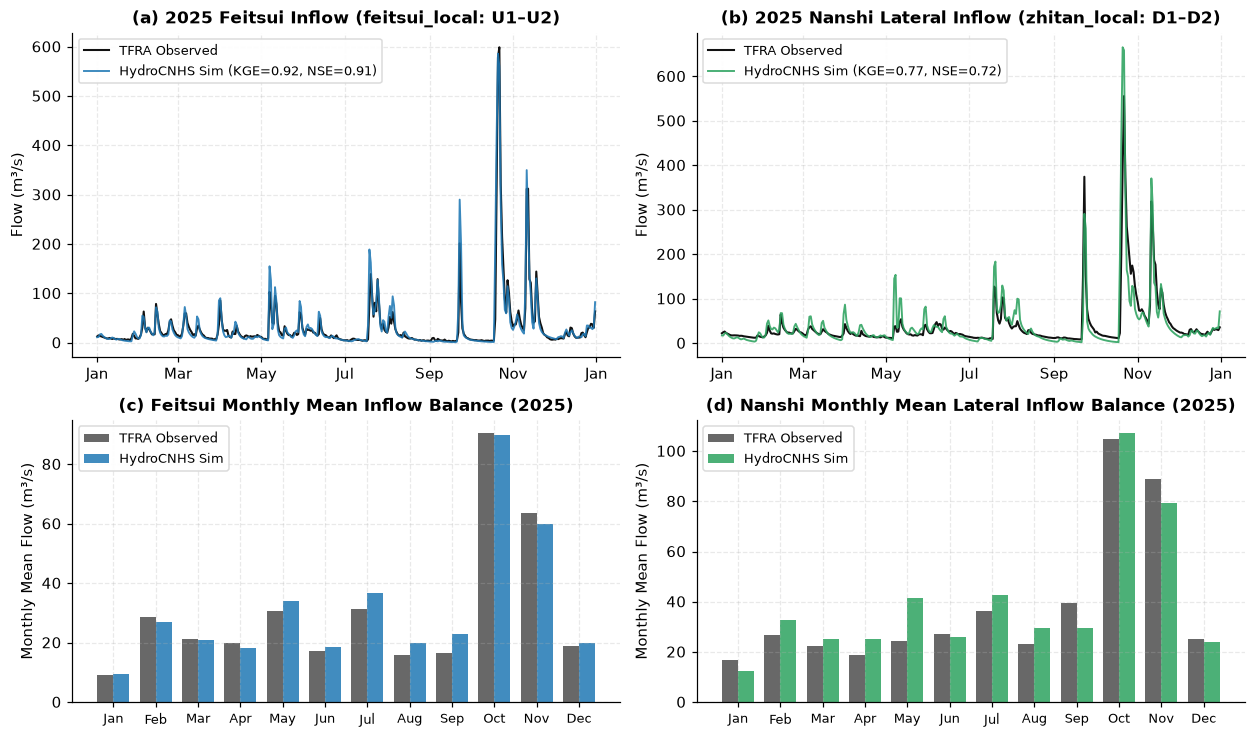

In [5]:
import math
import matplotlib.dates as mdates

def metrics(sim: np.ndarray, obs: np.ndarray) -> dict[str, float]:
    corr = float(np.corrcoef(sim, obs)[0, 1])
    kge = float(1.0 - math.sqrt(
        (corr - 1.0) ** 2
        + (sim.std(ddof=0) / obs.std(ddof=0) - 1.0) ** 2
        + (sim.mean() / obs.mean() - 1.0) ** 2
    ))
    nse = float(1.0 - np.sum((sim - obs) ** 2) / np.sum((obs - obs.mean()) ** 2))
    rmse = float(np.sqrt(np.mean((sim - obs) ** 2)))
    return {"KGE": kge, "NSE": nse, "RMSE": rmse}

cv_obs = pd.read_csv(hyd_dir / "cv_observations.csv.gz")
obs_2025 = cv_obs[(cv_obs["date"] >= "2025-01-01") & (cv_obs["date"] <= "2025-12-31")].copy()
sim_2025 = pub_pivot[(pub_pivot["date"] >= "2025-01-01") & (pub_pivot["date"] <= "2025-12-31")].copy()
df25 = obs_2025.merge(sim_2025, on="date", how="inner")
df25["dt"] = pd.to_datetime(df25["date"])
df25["month"] = df25["dt"].dt.month

m_feitsui = metrics(df25["feitsui_local"].to_numpy(), df25["feitsui_inflow_cms"].to_numpy())
m_nanshi = metrics(df25["zhitan_local"].to_numpy(), df25["zhitan_local_nanshi_cms"].to_numpy())

print("=== 2025 Out-of-Sample Daily Streamflow Metrics ===")
print(f"  Feitsui (feitsui_local) : KGE={m_feitsui['KGE']:.3f}, NSE={m_feitsui['NSE']:.3f}, RMSE={m_feitsui['RMSE']:.2f} m3/s")
print(f"  Nanshi  (zhitan_local)  : KGE={m_nanshi['KGE']:.3f}, NSE={m_nanshi['NSE']:.3f}, RMSE={m_nanshi['RMSE']:.2f} m3/s")

monthly = df25.groupby("month").agg(
    feitsui_obs=("feitsui_inflow_cms", "mean"),
    feitsui_sim=("feitsui_local", "mean"),
    nanshi_obs=("zhitan_local_nanshi_cms", "mean"),
    nanshi_sim=("zhitan_local", "mean"),
)
print("\n=== 2025 Annual Mean Flow & Volume Balance ===")
for name, o_col, s_col in [
    ("Feitsui (U1-U2)", "feitsui_inflow_cms", "feitsui_local"),
    ("Nanshi  (D1-D2)", "zhitan_local_nanshi_cms", "zhitan_local"),
]:
    o_mcm = df25[o_col].sum() * 86400 / 1e6
    s_mcm = df25[s_col].sum() * 86400 / 1e6
    bias_pct = 100.0 * (s_mcm - o_mcm) / o_mcm
    print(f"  {name}: Obs={o_mcm:7.1f} MCM | Sim={s_mcm:7.1f} MCM | Volume Bias={bias_pct:+.1f}%")

fig, axes = plt.subplots(2, 2, figsize=(11.5, 6.8), gridspec_kw={"height_ratios": [1.15, 1.0]})

# (a) Feitsui daily hydrograph
ax = axes[0, 0]
ax.plot(df25["dt"], df25["feitsui_inflow_cms"], color="#111111", lw=1.35, label="TFRA Observed")
ax.plot(df25["dt"], df25["feitsui_local"], color="#1f78b4", lw=1.25, alpha=0.88,
        label=f"HydroCNHS Sim (KGE={m_feitsui['KGE']:.2f}, NSE={m_feitsui['NSE']:.2f})")
ax.set_title("(a) 2025 Feitsui Inflow (feitsui_local: U1–U2)")
ax.set_ylabel("Flow (m³/s)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(loc="upper left", fontsize=8.3)

# (b) Nanshi daily hydrograph
ax = axes[0, 1]
ax.plot(df25["dt"], df25["zhitan_local_nanshi_cms"], color="#111111", lw=1.35, label="TFRA Observed")
ax.plot(df25["dt"], df25["zhitan_local"], color="#2ca25f", lw=1.25, alpha=0.88,
        label=f"HydroCNHS Sim (KGE={m_nanshi['KGE']:.2f}, NSE={m_nanshi['NSE']:.2f})")
ax.set_title("(b) 2025 Nanshi Lateral Inflow (zhitan_local: D1–D2)")
ax.set_ylabel("Flow (m³/s)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(loc="upper left", fontsize=8.3)

# (c) Feitsui monthly water balance
months = np.arange(1, 13)
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
w = 0.38
ax = axes[1, 0]
ax.bar(months - w/2, monthly["feitsui_obs"], width=w, color="#4d4d4d", alpha=0.85, label="TFRA Observed")
ax.bar(months + w/2, monthly["feitsui_sim"], width=w, color="#1f78b4", alpha=0.85, label="HydroCNHS Sim")
ax.set_title("(c) Feitsui Monthly Mean Inflow Balance (2025)")
ax.set_ylabel("Monthly Mean Flow (m³/s)")
ax.set_xticks(months)
ax.set_xticklabels(month_labels, fontsize=8.5)
ax.legend(loc="upper left", fontsize=8.3)

# (d) Nanshi monthly water balance
ax = axes[1, 1]
ax.bar(months - w/2, monthly["nanshi_obs"], width=w, color="#4d4d4d", alpha=0.85, label="TFRA Observed")
ax.bar(months + w/2, monthly["nanshi_sim"], width=w, color="#2ca25f", alpha=0.85, label="HydroCNHS Sim")
ax.set_title("(d) Nanshi Monthly Mean Lateral Inflow Balance (2025)")
ax.set_ylabel("Monthly Mean Flow (m³/s)")
ax.set_xticks(months)
ax.set_xticklabels(month_labels, fontsize=8.5)
ax.legend(loc="upper left", fontsize=8.3)

fig.tight_layout()
plt.show()


## Key Takeaways & Next Step

- **Zero double-counting by construction:** `validate_bindings` guarantees that `feitsui_local` (`U1`, aggregating `U1+U2`) and `zhitan_local` (`D1`, aggregating `D1+D2`) form a disjoint partition of the 4-subbasin watershed.
- **Bit-for-bit hydrology coupling:** Re-running the pinned native `HydroCNHS` (`GWLF` + `Lohmann`) model reproduced `examples/multi_reservoir/inflows.csv` within floating-point rounding tolerance (`< 1e-6 m³/s`).
- **Strong out-of-sample skill:** Across the 3-year validation window (`2023–2025`), Feitsui inflow achieves `KGE = 0.912` (`NSE = 0.886`) and combined Zhitan flow achieves `KGE = 0.916` (`NSE = 0.831`).
- **Next Module →** [`Module 04: Multi-Reservoir Hybrid Cascade (Xindian River)`](../04_multi_reservoir_hybrid_cascade/README.md) couples these validated inflows into the 2-reservoir cascade (`feitsui → zhitan → xindian_outlet`) and compares dual Rule-based vs. Joint-dispatch Hybrid LLM operation.
